In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pandas import pivot


In [6]:
data = pd.read_csv('superstore_dataset2012.csv')
df = pd.DataFrame(data)

# Exploración y preparación de los datos

In [26]:
# Tamaño del dataset
df.count()

Row ID            4246
Order ID          4246
Order Date        4246
Ship Date         4246
Ship Mode         4246
Customer ID       4246
Customer Name     4246
Segment           4246
City              4246
State             4246
Country           4246
Postal Code        823
Market            4246
Region            4246
Product ID        4246
Category          4246
Sub-Category      4246
Product Name      4246
Sales             4246
Quantity          4246
Discount          4246
Profit            4246
Shipping Cost     4246
Order Priority    4246
dtype: int64

In [21]:
# Primeras lineas del dataset
df.head(5)
df.tail(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
4241,33684,CA-2012-145065,2012-12-12,15-12-2012,First Class,DK-13375,Dennis Kane,Consumer,San Diego,California,...,OFF-FA-10001229,Office Supplies,Fasteners,Staples,7.86,2,0.0,3.6156,0.92,Medium
4242,42063,MO-2012-4720,2012-12-12,15-12-2012,Second Class,JH-5910,Jonathan Howell,Consumer,Casablanca,Grand Casablanca,...,OFF-STA-10004484,Office Supplies,Art,"Stanley Pens, Water Color",26.46,2,0.0,8.4600,0.59,Medium
4243,42062,MO-2012-4720,2012-12-12,15-12-2012,Second Class,JH-5910,Jonathan Howell,Consumer,Casablanca,Grand Casablanca,...,OFF-ACC-10000798,Office Supplies,Binders,"Acco Hole Reinforcements, Economy",6.66,1,0.0,0.5700,0.45,Medium
4244,36014,CA-2012-129042,2012-12-12,17-12-2012,Standard Class,EM-13960,Eric Murdock,Consumer,Baltimore,Maryland,...,OFF-AR-10001662,Office Supplies,Art,Rogers Handheld Barrel Pencil Sharpener,8.22,3,0.0,2.2194,0.29,Medium
4245,37078,CA-2012-155586,2012-12-12,16-12-2012,Second Class,XP-21865,Xylona Preis,Consumer,Chico,California,...,OFF-AR-10001547,Office Supplies,Art,Newell 311,2.21,1,0.0,0.5967,0.20,Medium


In [32]:
# Listado de columnas
df.dtypes

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
City                         str
State                        str
Country                      str
Postal Code              float64
Market                       str
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
Shipping Cost            float64
Order Priority               str
dtype: object

In [33]:
# Conversión de tipos
df['Order Date'] = pd.to_datetime(df['Order Date'], errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], errors='coerce', format='mixed')
df.dtypes

Row ID                     int64
Order ID                     str
Order Date        datetime64[us]
Ship Date         datetime64[us]
Ship Mode                    str
Customer ID                  str
Customer Name                str
Segment                      str
City                         str
State                        str
Country                      str
Postal Code              float64
Market                       str
Region                       str
Product ID                   str
Category                     str
Sub-Category                 str
Product Name                 str
Sales                    float64
Quantity                   int64
Discount                 float64
Profit                   float64
Shipping Cost            float64
Order Priority               str
dtype: object

In [31]:
# Valores faltantes
df.isna().sum()
df.isnull().sum()

Row ID               0
Order ID             0
Order Date           0
Ship Date            0
Ship Mode            0
Customer ID          0
Customer Name        0
Segment              0
City                 0
State                0
Country              0
Postal Code       3423
Market               0
Region               0
Product ID           0
Category             0
Sub-Category         0
Product Name         0
Sales                0
Quantity             0
Discount             0
Profit               0
Shipping Cost        0
Order Priority       0
dtype: int64

In [38]:
df.describe()

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit,Shipping Cost
count,4246.000000,4246,4246,823.000000,4246.000000,4246.000000,4246.000000,4246.000000,4246.000000
mean,25248.240226,2012-06-23 23:10:29.109750,2012-08-13 20:46:41.318888,48442.910085,237.029481,3.444183,0.146615,27.698282,24.539708
min,66.000000,2012-01-02 00:00:00,2012-01-08 00:00:00,1040.000000,1.112000,1.000000,0.000000,-1806.240000,0.030000
25%,12424.250000,2012-04-01 00:00:00,2012-06-13 00:00:00,19140.000000,30.564000,2.000000,0.000000,-0.062700,2.610000
50%,24848.000000,2012-06-12 00:00:00,2012-08-15 00:00:00,44256.000000,82.527900,3.000000,0.000000,9.029400,7.600000
75%,37522.750000,2012-10-02 00:00:00,2012-10-17 00:00:00,78207.000000,245.814750,5.000000,0.200000,35.902500,23.530000
max,51289.000000,2012-12-12 00:00:00,2012-12-19 00:00:00,99207.000000,5759.964000,14.000000,0.800000,2229.024000,759.470000
std,14711.393243,NaN,NaN,32118.342697,426.974969,2.228431,0.216120,147.459878,50.422150


# Visualizaciones univariantes con matplotlib

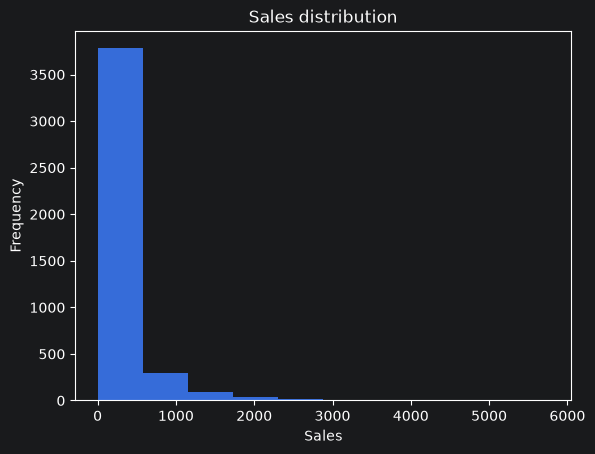

In [42]:
# Histograma de ventas
plt.hist(df['Sales'])
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.title('Sales distribution')
plt.show()

Se puede apreciar que la mayoría de las ventas se recogen entre 0 y 500. Existen datos de más de 5000€ pero son muy pocos.

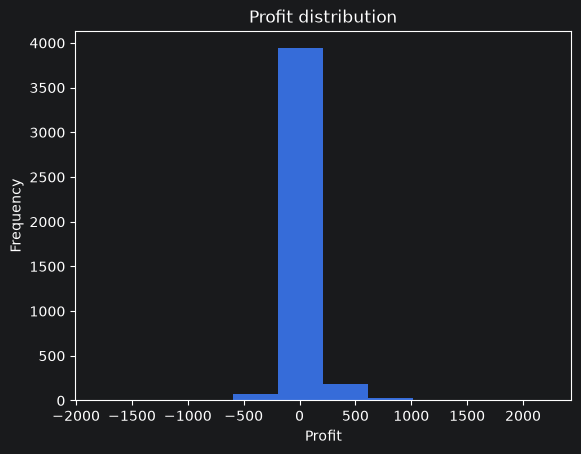

In [43]:
# Histograma de beneficios
plt.hist(df['Profit'])
plt.xlabel('Profit')
plt.ylabel('Frequency')
plt.title('Profit distribution')
plt.show()

Se puede observar claramente como el beneficio tiende a encontrarse alrededor de 0. La maroría de los datos recogen un balance ligeramente positivo. Existen observaciones con beneficio muy negativo y muy positivo pero son poco frecuentes.

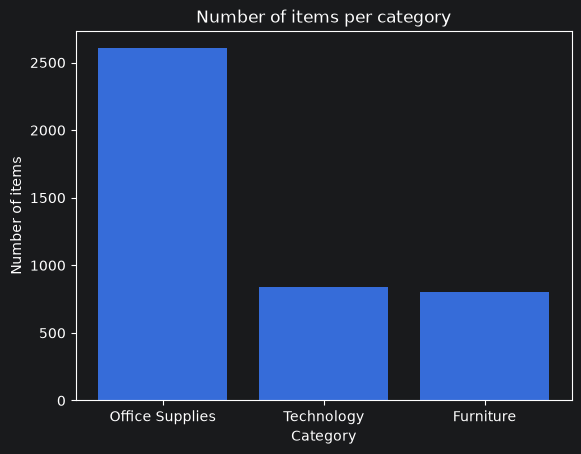

In [44]:
# Gráfico de barras Categoría
category_counts = df['Category'].value_counts()
plt.bar(category_counts.index, category_counts.values)
plt.xlabel('Category')
plt.ylabel('Number of items')
plt.title('Number of items per category')
plt.show()

La mayoría de observaciones presentan la categoría 'Office supplies. Se aprecia en el gráfico que más del doble de las cantidades observadas de otras categorías.

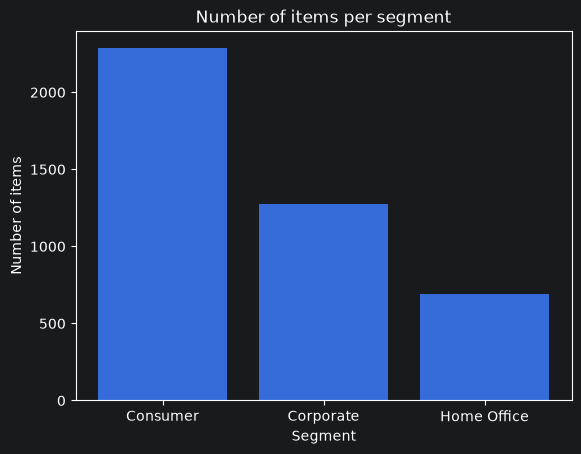

In [45]:
segment_count = df['Segment'].value_counts()
plt.bar(segment_count.index, segment_count.values)
plt.xlabel('Segment')
plt.ylabel('Number of items')
plt.title('Number of items per segment')
plt.show()

La cantidad de observaciones relativas a cada segmento es bastante dispar. Se observan la mayoría del segmento 'Consumer'. La mitad aproximadamente de 'Corporate' y poco más de un cuarto relativas a 'Home Office'.

# Visualizaciones univariantes con Seaborn

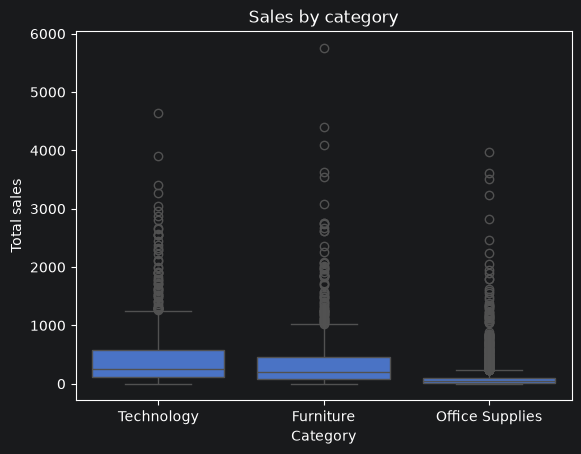

In [46]:
# Gráfico de caja (boxplot) comparado por categoría
sns.boxplot(data=df, x='Category', y='Sales')

plt.xlabel('Category')
plt.ylabel('Total sales')
plt.title('Sales by category')
plt.show()

Se puede observar claramente que la mayoría de ventas se encuentran localizadas (como hemos mencionado antes) entre 0 y 500-600€. Vemos que hay muchos datos considerados outliers por lo que se puede ver con claridad la variabilidad de los datos. También se pueden observar que la mayoría de los datos de ventas recogidos para 'Office Supplies' se localizan fuera de los cuartiles 1 y 3.

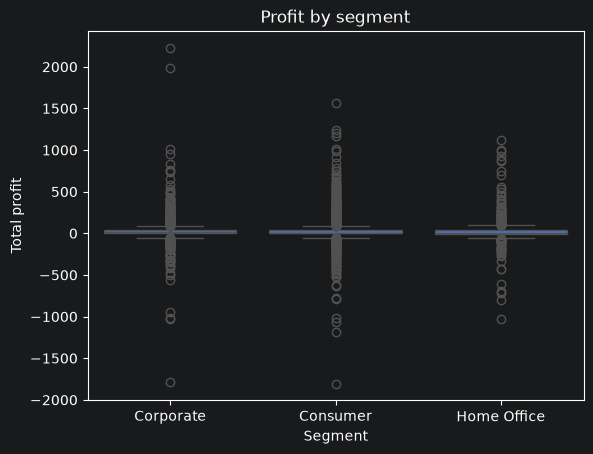

In [47]:
# Gráfico de violín (violinplot) comparado por segmento
sns.boxplot(data=df, x='Segment', y='Profit')

plt.xlabel('Segment')
plt.ylabel('Total profit')
plt.title('Profit by segment')
plt.show()

Comparando el beneficio por segmento se observa que no existe una clara relación entre ambas variables. La mayoría de los datos recogidos se localizan en los puntos exteriores a los cuartiles 1 y 3 por lo que son considerados como 'outliers'.

# Gráficos bivariantes con Matplotlib

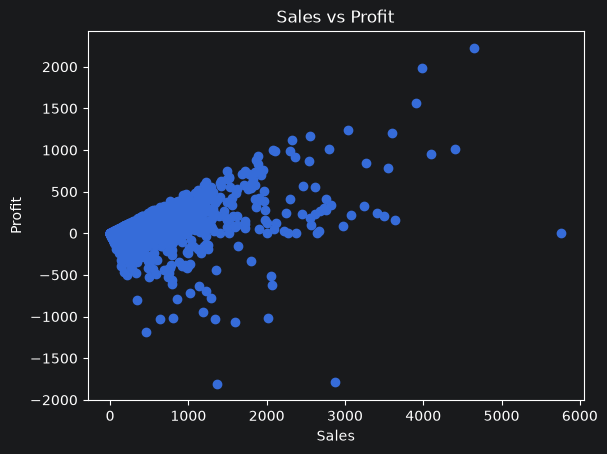

In [48]:
# Gráfico de dispersión ventas vs beneficios
plt.scatter(df['Sales'], df['Profit'])
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.title('Sales vs Profit')
plt.show()

Se puede apreciar que existe una tendencia positiva entre las ventas y el beneficio obtenido por las mismas. La mayoría de datos se recogen entre 0 y 1000-2000€ con beneficios en torno al 0 aunque con tendencia ligeramente positiva.

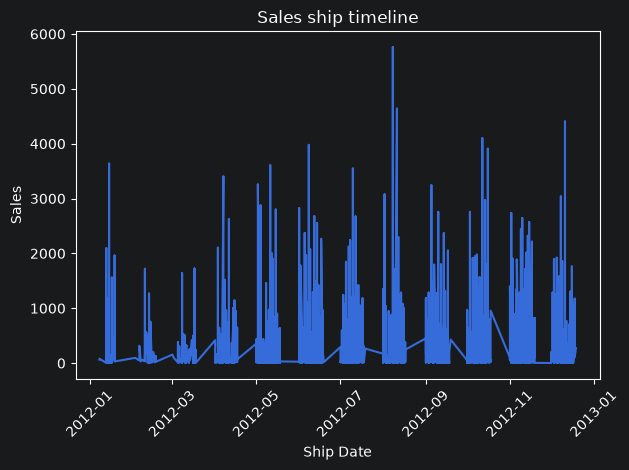

In [56]:
# Gráfico de linea evolución temporal ventas
df_sorted = df.sort_values(by='Ship Date')
plt.plot(df_sorted['Ship Date'], df_sorted['Sales'], linestyle='-')
plt.xlabel('Ship Date')
plt.ylabel('Sales')
plt.title('Sales ship timeline')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Viendo la evolución de la fecha de envío se puede ver que existen saltos en el tiempo es decir no todos los días se realizan envíos. En agosto se puede apreciar un pico de envíos que destaca frente a otros meses y se puede volver a apreciar otro (aunque ligeramente inferior) en diciembre.

# Gráficos bivariantes con Seaborn

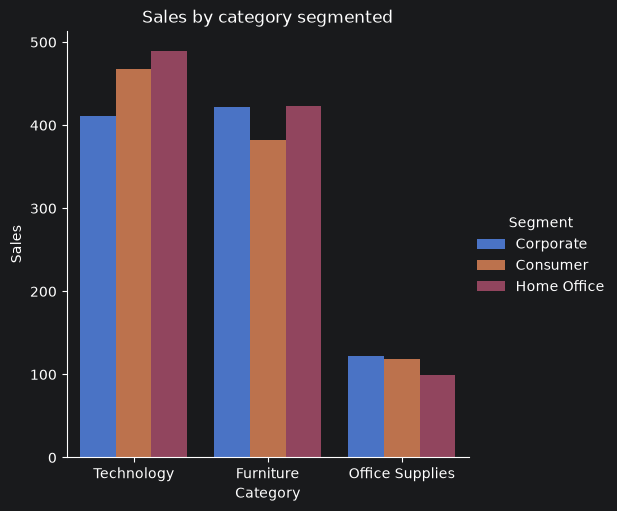

In [59]:
# Gráfico de barras agrupadas Ventas por ccategoría y segmento
sns.catplot(df, x='Category', y='Sales', hue='Segment', kind='bar', errorbar=None)
plt.xlabel('Category')
plt.ylabel('Sales')
plt.title('Sales by category segmented')
plt.show()

Segmentando las ventas por categoría y segmento se puede observar como hay una tendencia en tecnología para 'Home Office' seguido de 'Consumer' mientras que en el caso de muebles, 'Corporate' y 'Home office' quedarían muy alineados y sería 'Consumer' el que se quedaría atrás. En el caso de 'Office Supplies' son las ventas para 'Home office' las que destacan menos. La relación de ventas por categoría nos indica que claramente lo más demandado es tecnología seguido de muebles (como ya habíamos visto antes).

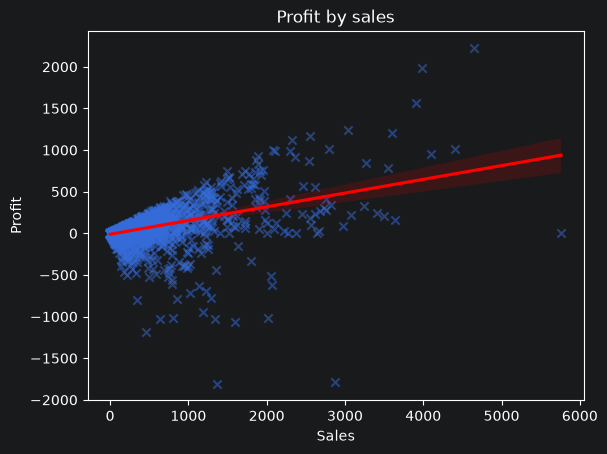

In [67]:
# Gráfico de dispersión con regresión de Ventas frente a Beneficios
sns.regplot(df, x='Sales', y='Profit', marker='x', line_kws={'color': 'red'}, scatter_kws={'alpha': 0.5})
plt.xlabel('Sales')
plt.ylabel('Profit')
plt.title('Profit by sales')
plt.show()

En este gráfico volvemos a analizar ventas y beneficios pero utilizando seaborn para mostrar la linea de regresión que nos indica la clara tendencia positiva de los datos. A mayor cantidad de ventas mayor es el beneficio obtenido. Pese a que la tendencia es positiva se aprecia (como se ha mencionado anteriormente) que las ventas se localizan entre los puntos más bajos de la gráfica. En consecuencia los beneficios se localizan en la parte central de la misma tendiendo al cero.

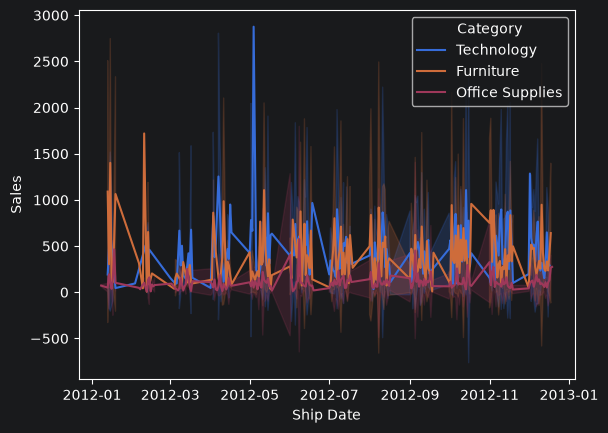

In [70]:
# Gráfico de lineas evolución de ventas
df_sorted = df.sort_values(by='Ship Date')
sns.lineplot(df, x='Ship Date', y='Sales', hue='Category', errorbar='sd')
plt.show()

En este gráfico se puede ver la evolución temporal de los envíos comparado con las ventas y segmentado por categoría. Se observa que en mayo hubo un pico bastante elevado de ventas en tecnología. También se puede ver que en lo referente a muebles existen picos y caídas muy claras lo que implica que no son continuadas. Como ya se ha mencioando antes las ventas de 'Office Supplies' se quedan siempre de forma discreta en la parte baja de la gráfica y no se aprecian a priori picos concretos.

# Visualización multivariante con Seaborn

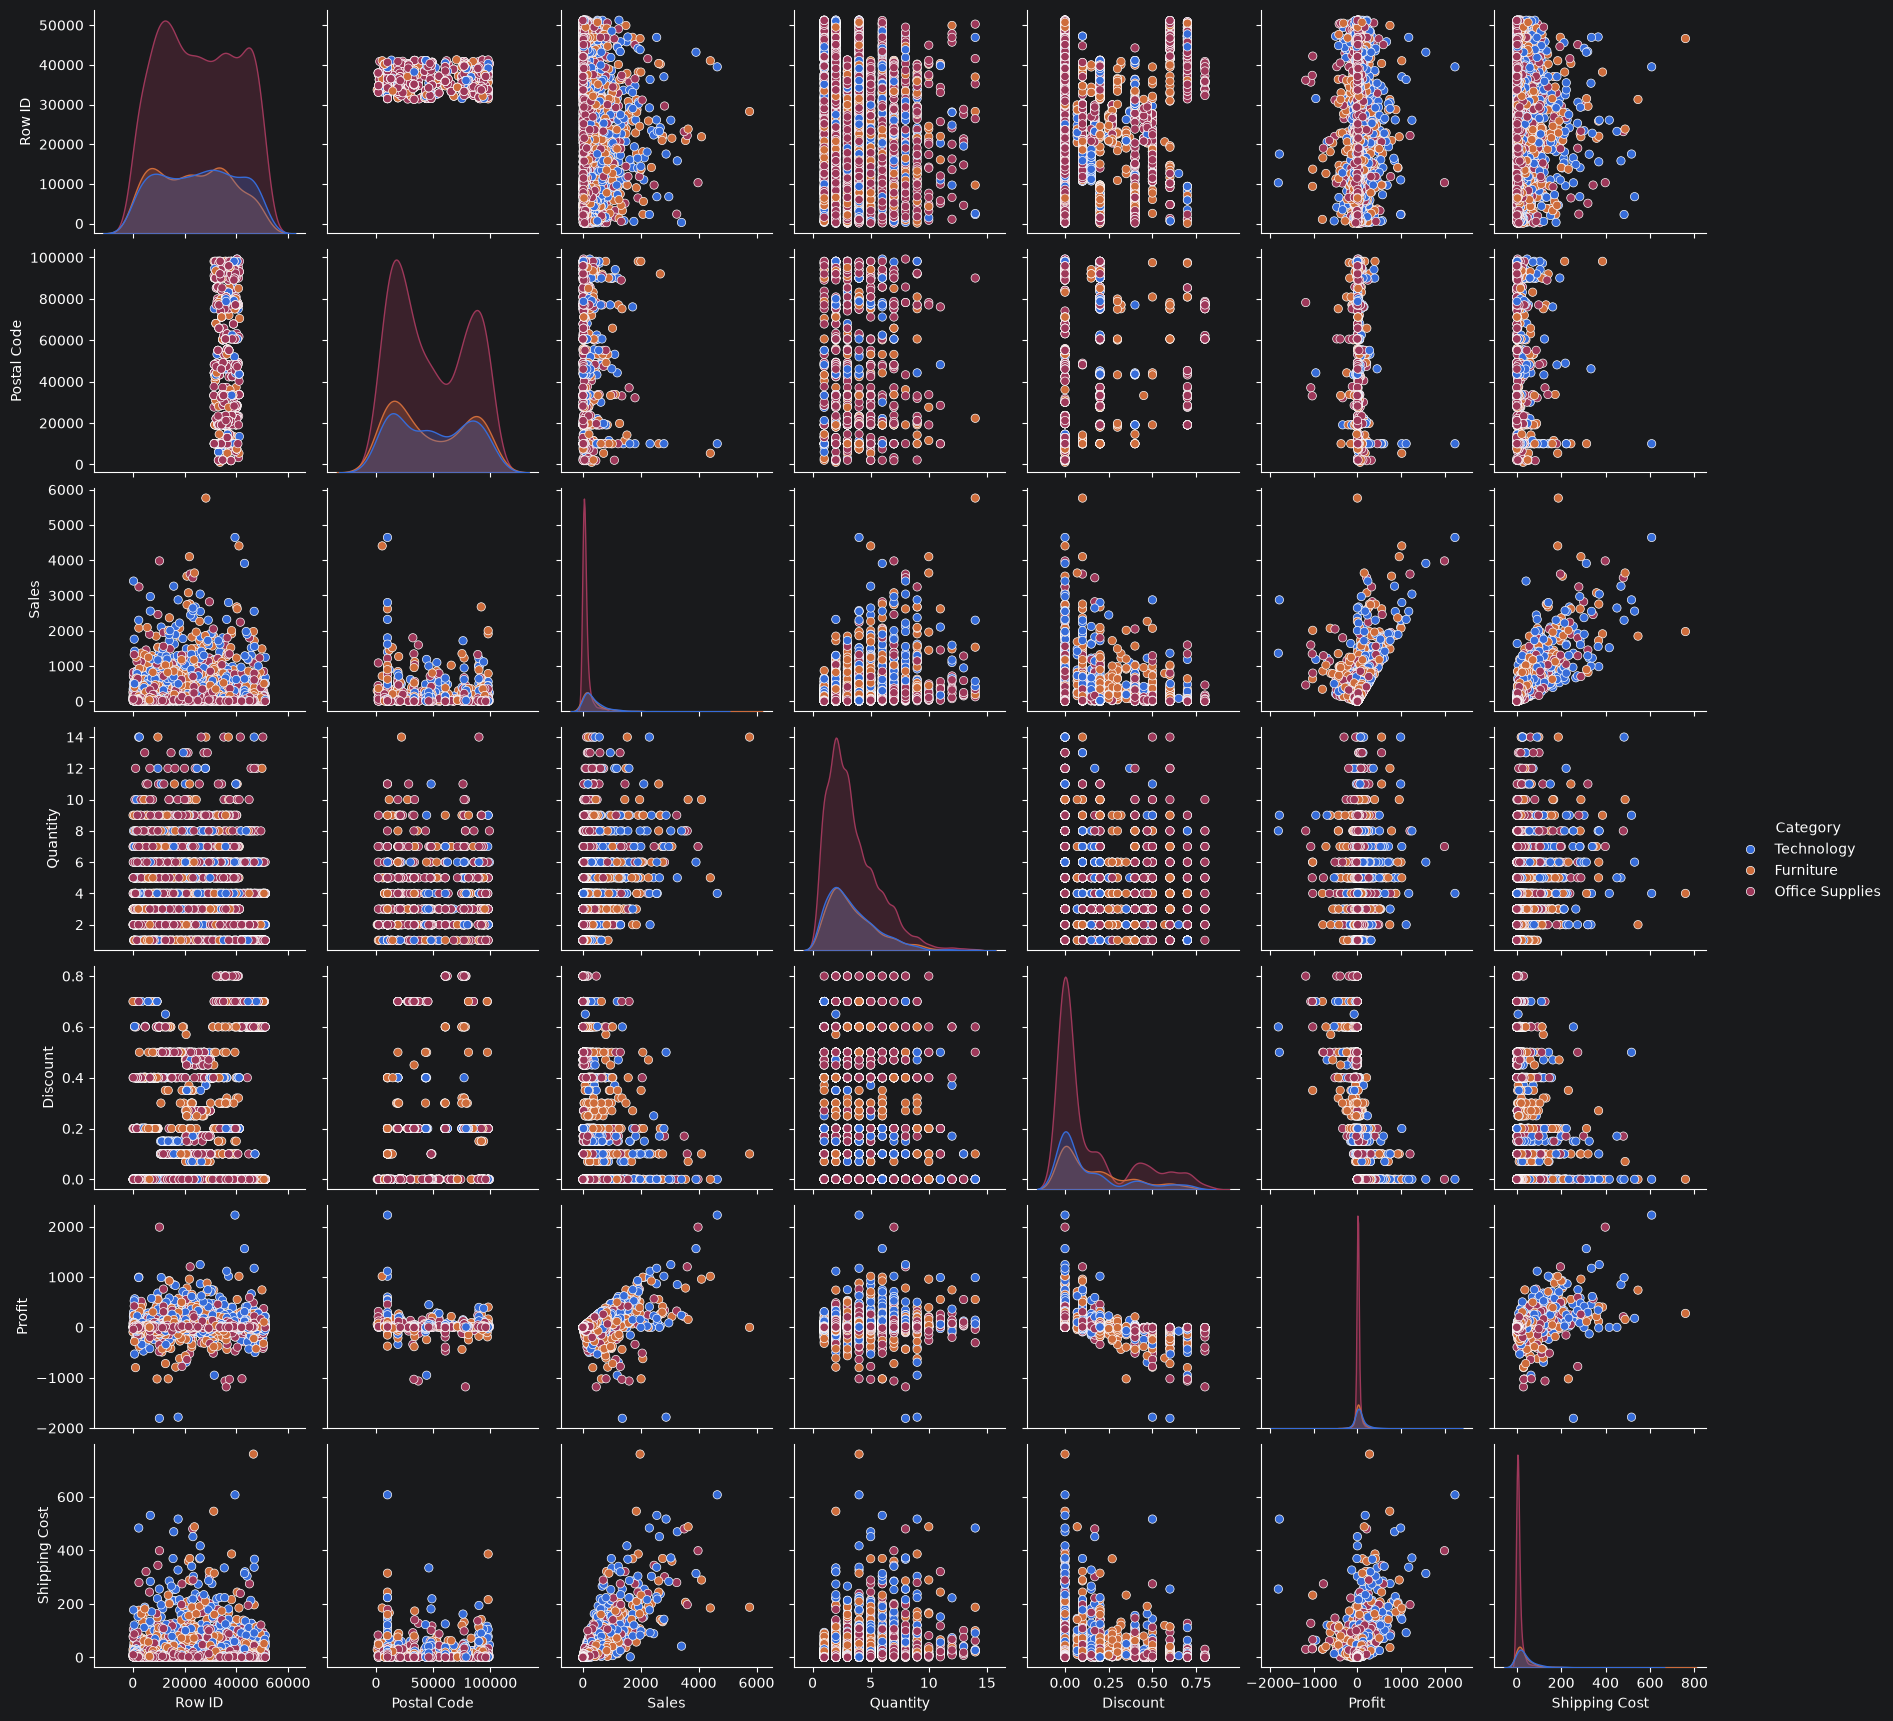

In [71]:
# Pairplot de relación de variables numéricas
sns.pairplot(df, hue='Category')
plt.show()

Gracias a este pair plot de valores numéricos se puede ver que existe una clara relación positiva entre ventas y coste de envío. También entre ventas y beneficios (aunque esta es más discreta). Lo mismo que si comparamos beneficio con coste de envío. En cuanto a la diagonal, vemos que la cantidad de ventas se reparte ligeramente homogénea en cuanto a frecuencia. No podemos decir lo mismo de otras variables como Beneficio o Coste de envío.

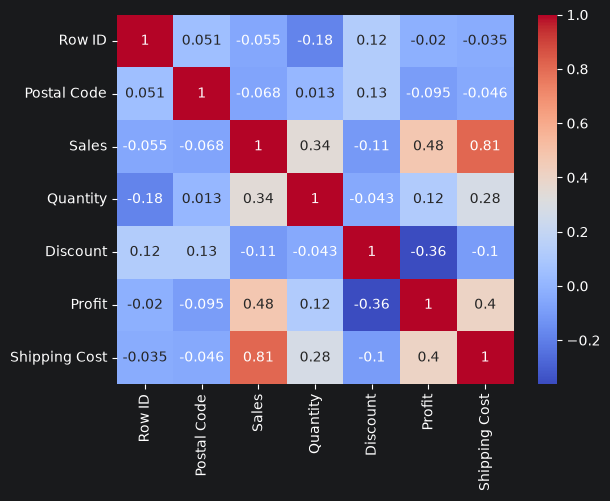

In [72]:
# Heatmap de correlación de variables numéricas
corr = df.select_dtypes(include=['float64', 'int64']).corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.show()

Con el mapa de calor de correlaciones confirmamos lo mencionado con anterioridad: existe una muy clara relación entre ventas y coste de envío. Una prelación más sutil entre ventas y beneficios. El resto de variables prácticamente no presentan una correlación elevada.

# Organiza visualizaciones en subplots

In [76]:
import matplotlib.gridspec as gridspec

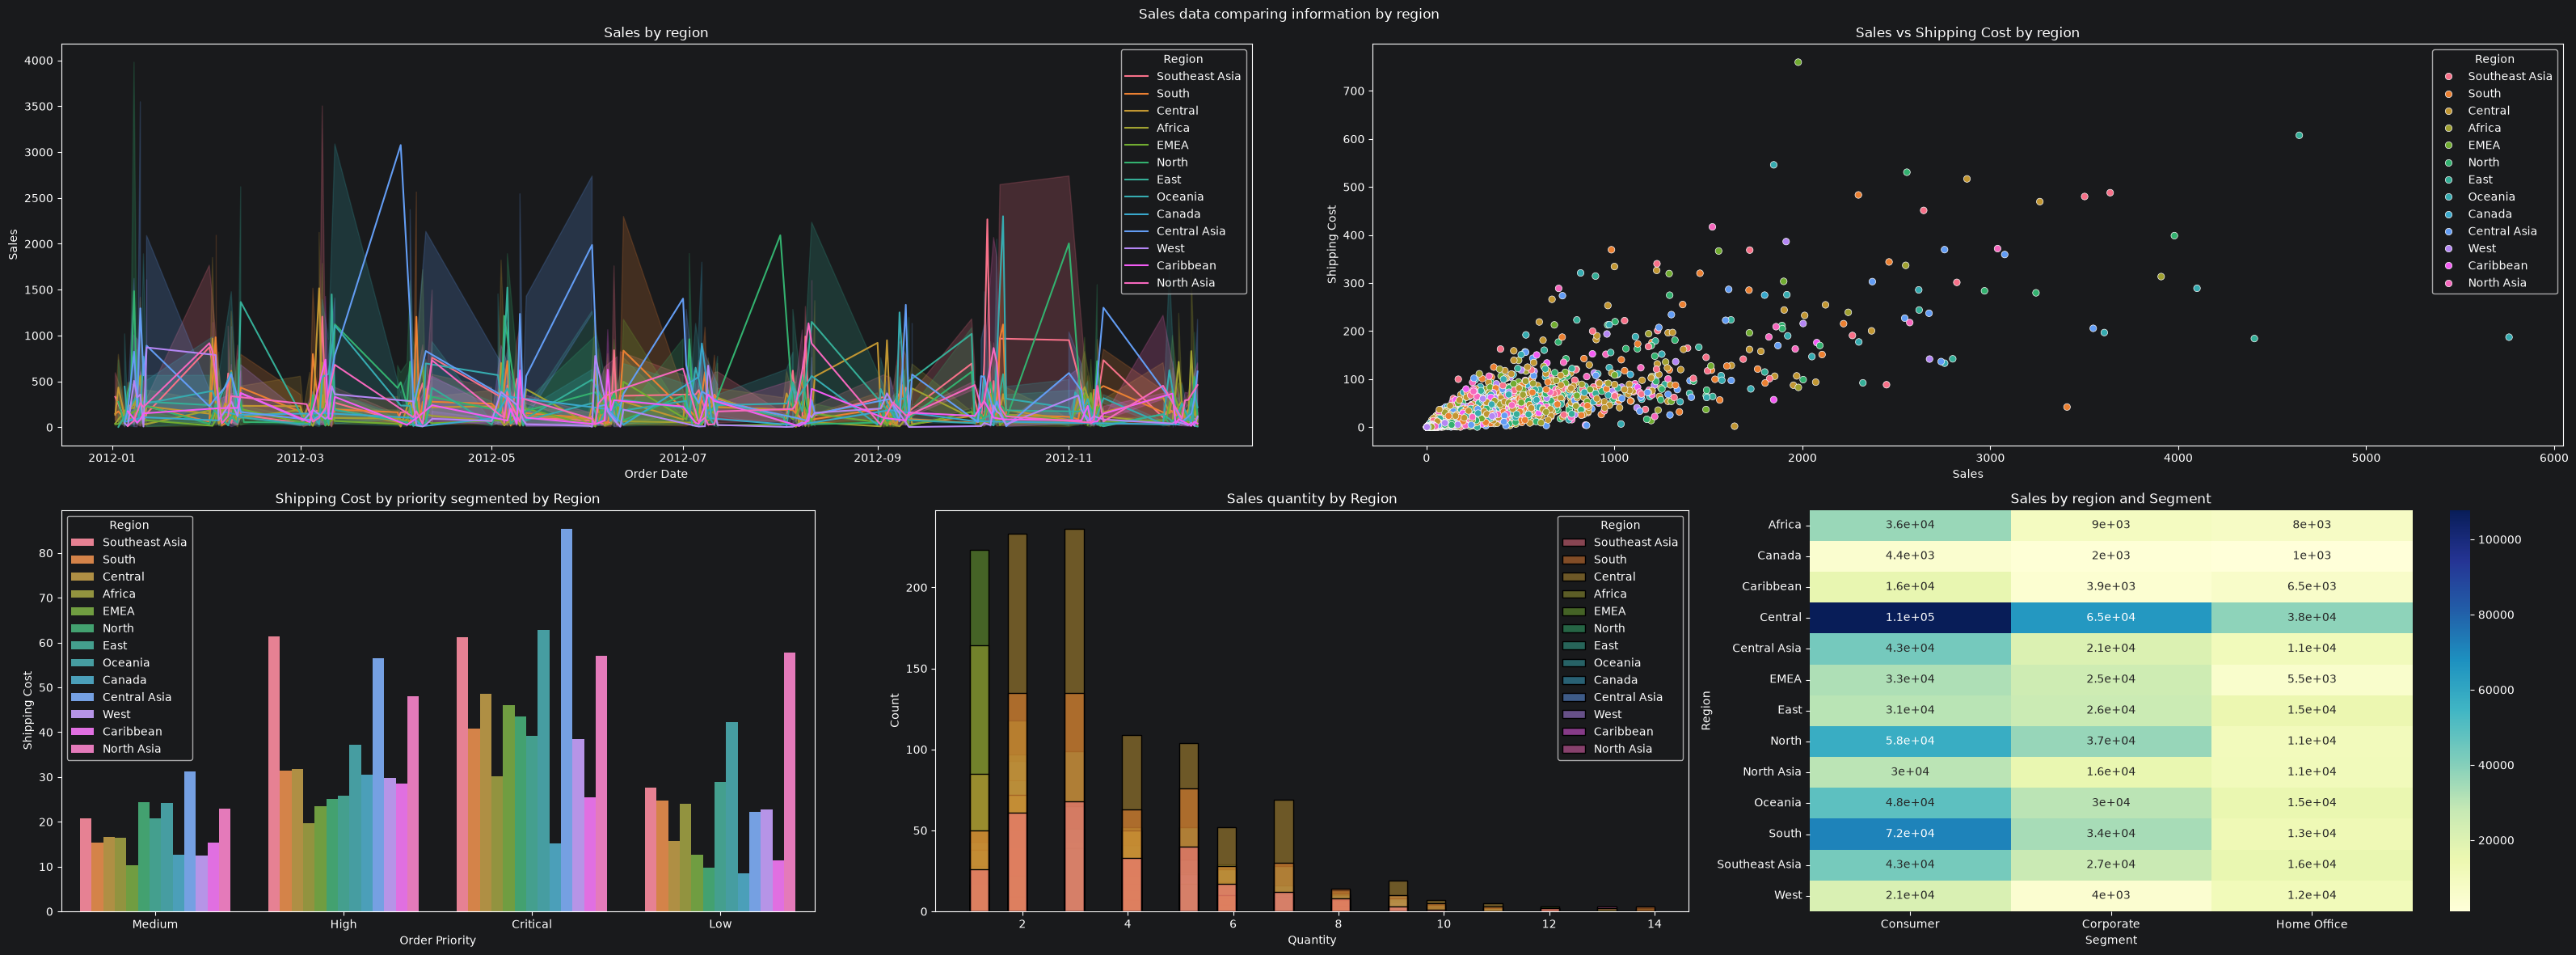

In [88]:
# Crear una figura con seis ejes en dos filas (5 gráficos)
fig = plt.figure(figsize=(32,12))
gs = gridspec.GridSpec(2, 6, figure=fig)
ax1 = fig.add_subplot(gs[0, 0:3])
ax2 = fig.add_subplot(gs[0, 3:6])
ax3 = fig.add_subplot(gs[1, 0:2])
ax4 = fig.add_subplot(gs[1, 2:4])
ax5 = fig.add_subplot(gs[1, 4:6])

# Gráfico 1: De lineas Ventas por región
sns.lineplot(df, x='Order Date', y='Sales', hue='Region', ax=ax1)
ax1.set_title('Sales by region')

# Gráfico 2: De dispersión Ventas por shipping cost
sns.scatterplot(df, x='Sales', y='Shipping Cost', hue='Region', ax=ax2)
ax2.set_title('Sales vs Shipping Cost by region')

# Gráfico 3: De barras comparativa priority y shipping cost
sns.barplot(df, x='Order Priority', y='Shipping Cost', hue='Region', errorbar=None, ax=ax3)
ax3.set_title('Shipping Cost by priority segmented by Region')

# Gráfico 4: Histograma de cantidad de ventas
sns.histplot(df, x='Quantity', hue='Region', ax=ax4)
ax4.set_title('Sales quantity by Region')

# Gráfico 5: Diagrama de calor Segment by region
pivot_ax5 = df.pivot_table(index='Region', columns='Segment', values='Sales', aggfunc=sum)
sns.heatmap(pivot_ax5, annot=True, cmap='YlGnBu', ax=ax5)
ax5.set_title('Sales by region and Segment')

fig.suptitle('Sales data comparing information by region')

plt.tight_layout()
plt.show()

fig.savefig('superstore_by_region.png', bbox_inches='tight')

Finalizamos el análisis con un gráfico comparativo de ventas por región. Podemos ver que las ventas no se distribuyen por región siguiendo una tendencia homogénea. Hay picos que marcan algunos valores pero la mayoría de las mismas mantienen un perfil bajo. En el segundo gráfico se puede ver la clara tendencia positiva entre ventas y coste de envío. A mayor quantía en la venta, mayor es el coste de envío. Si prestamos atención a la prioridad de los envíos con respecto a la región, vemos que la cantidad de pedidos con prioridad crítica es bastante elevada. Destacan sobretodo las zonas asiáticas. Si prestamos atención a las cantidades de productos vendidas nos damos cuenta que la tendencia es pedir entre 1 y 3 unidades pro producto. Comparado el dato con respecto a la región vemos que hay un amplio abanico de resultados. Para terminar, se ha creado un mapa de calor para comparar las ventas por región segmentadas. Se puede ver con total claridad que destacan los consumidores finales en la zona central.